 
# Reinforcement Learning: Spacecraft Landing

## Research Question

Can a reinforcement learning agent learn to land a spacecraft safely while minimizing fuel consumption?

## Motivation

Landing a spacecraft requires precise control of its velocity and altitude.

If the spacecraft descends too quickly, it will crash. If it uses too much thrust, it wastes fuel.

In this project, we use reinforcement learning to teach an agent how to control the spacecraft's engine.

## Objectives

1. Simulate vertical spacecraft motion under gravity.
2. Implement a Q-Learning agent.
3. Train the agent to choose appropriate thrust levels.
4. Visualize the learning process.
5. Compare spacecraft trajectories before and after training.
6. Create an animation of the landing.

## Reinforcement Learning Approach

We use Q-Learning, a model-free reinforcement learning algorithm.

The agent observes the spacecraft's altitude and velocity, selects a thrust action, and receives a reward based on its performance.

Through repeated attempts, the agent learns a control policy that aims to achieve a safe landing.


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

np.random.seed(42)



## 1. Physical Model

We simulate a spacecraft descending vertically toward a landing surface.

The spacecraft experiences two forces:

- Gravity, acting downward.
- Engine thrust, acting upward.

Newton's second law gives:

$$
a = \frac{F}{m} - g
$$

We update velocity and altitude using a simple numerical integration scheme:

$$
v_{t+\Delta t} = v_t + a\Delta t
$$

$$
h_{t+\Delta t} = h_t + v_{t+\Delta t}\Delta t
$$

We assume constant spacecraft mass and ignore air resistance.

This simplified model allows us to focus on learning a safe landing strategy.


In [2]:

g = 9.81
mass = 1000
dt = 0.2

thrust_levels = [0, 5000, 10000, 15000, 20000]

def reset():
    height = 100.0
    velocity = -5.0
    return height, velocity

def step(height, velocity, action):
    thrust = thrust_levels[action]

    acceleration = thrust / mass - g

    velocity = velocity + acceleration * dt
    height = height + velocity * dt

    done = height <= 0

    reward = -0.1 - 0.00001 * thrust

    if done:
        height = 0

        if abs(velocity) < 2:
            reward += 100
        else:
            reward -= 100

    return height, velocity, reward, done



## 2. Initial Simulation: No Engine Control

Before training the reinforcement learning agent, we simulate a spacecraft falling without engine thrust.

This provides a baseline for comparison.

We expect the spacecraft to accelerate downward due to gravity and reach the ground with a high impact velocity.

Later, we will compare this trajectory with the learned landing strategy.


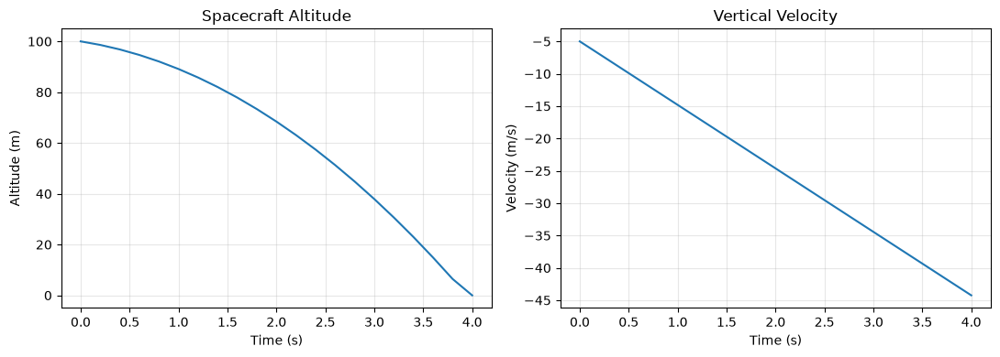

Impact velocity: -44.24 m/s


In [3]:

height, velocity = reset()

heights = [height]
velocities = [velocity]
times = [0]

for i in range(200):
    height, velocity, reward, done = step(
        height, velocity, action=0
    )

    heights.append(height)
    velocities.append(velocity)
    times.append((i + 1) * dt)

    if done:
        break

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(times, heights)
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Altitude (m)")
axes[0].set_title("Spacecraft Altitude")
axes[0].grid(alpha=0.3)

axes[1].plot(times, velocities)
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Velocity (m/s)")
axes[1].set_title("Vertical Velocity")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Impact velocity:", round(velocity, 2), "m/s")



The simulation shows how the spacecraft behaves without engine thrust.

As time increases, the altitude decreases and the vertical velocity becomes more negative.

This happens because gravity continuously accelerates the spacecraft downward.

The spacecraft eventually reaches the ground with a large downward velocity, resulting in a crash.

This demonstrates why active thrust control is necessary for a safe landing.

In the next step, we will introduce a reinforcement learning agent that learns when to activate the engine.



## 3. Reinforcement Learning with Q-Learning

We now introduce a reinforcement learning agent.

The agent observes two variables:

- Spacecraft altitude
- Vertical velocity

Based on these observations, it chooses one of five thrust levels.

We use Q-Learning to estimate which action is best for each state.

The agent receives a positive reward for landing safely and a negative reward for crashing.

It also receives small penalties for time and engine use.

The goal is to learn a control policy that balances landing safety and fuel efficiency.


In [4]:

# State bins
height_bins = np.linspace(0, 100, 21)
velocity_bins = np.linspace(-60, 20, 41)

def get_state(height, velocity):
    h = np.digitize(height, height_bins)
    v = np.digitize(velocity, velocity_bins)

    h = np.clip(h, 0, len(height_bins))
    v = np.clip(v, 0, len(velocity_bins))

    return int(h), int(v)

# Q-table
Q = np.zeros((
    len(height_bins) + 1,
    len(velocity_bins) + 1,
    len(thrust_levels)
))

print("Q-table shape:", Q.shape)


Q-table shape: (22, 42, 5)


In [5]:

alpha = 0.1
gamma = 0.99
epsilon = 1.0

episodes = 5000
rewards = []
successes = []

for episode in range(episodes):
    height, velocity = reset()
    total_reward = 0
    done = False

    for t in range(300):
        state = get_state(height, velocity)

        if np.random.rand() < epsilon:
            action = np.random.randint(len(thrust_levels))
        else:
            action = np.argmax(Q[state])

        new_height, new_velocity, reward, done = step(
            height, velocity, action
        )

        next_state = get_state(new_height, new_velocity)

        target = reward
        if not done:
            target += gamma * np.max(Q[next_state])

        Q[state][action] += alpha * (
            target - Q[state][action]
        )

        total_reward += reward
        height, velocity = new_height, new_velocity

        if done:
            break

    rewards.append(total_reward)
    successes.append(done and abs(velocity) < 2)

    epsilon = max(0.05, epsilon * 0.999)

print("Training complete!")
print("Success rate (last 100 episodes):",
      np.mean(successes[-100:]))


Training complete!
Success rate (last 100 episodes): 0.94



## 4. Investigating Learning Progress

In this experiment, we investigate how the spacecraft's landing performance changes as the reinforcement learning agent gains more experience.

We gradually increase the number of training episodes and measure the success rate.

We expect the agent to improve its landing strategy through repeated trial and error.

We will examine whether additional training leads to safer landings and higher rewards.


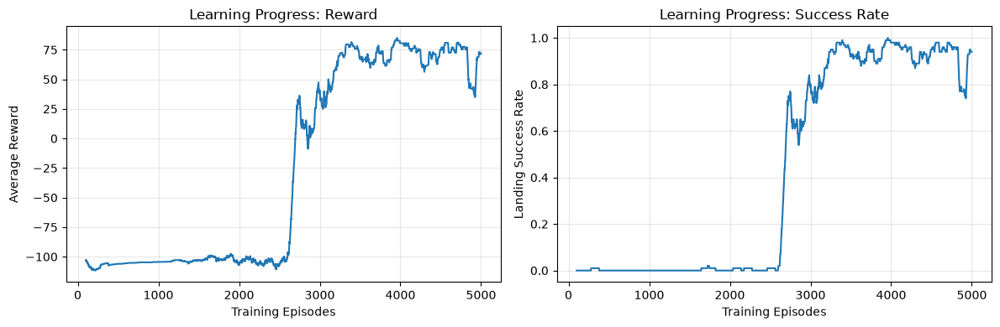

In [6]:

# Calculate moving averages
window = 100

avg_rewards = np.convolve(
    rewards,
    np.ones(window) / window,
    mode="valid"
)

avg_success = np.convolve(
    np.array(successes, dtype=float),
    np.ones(window) / window,
    mode="valid"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    np.arange(window, len(rewards) + 1),
    avg_rewards
)
axes[0].set_xlabel("Training Episodes")
axes[0].set_ylabel("Average Reward")
axes[0].set_title("Learning Progress: Reward")
axes[0].grid(alpha=0.3)

axes[1].plot(
    np.arange(window, len(successes) + 1),
    avg_success
)
axes[1].set_xlabel("Training Episodes")
axes[1].set_ylabel("Landing Success Rate")
axes[1].set_title("Learning Progress: Success Rate")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


These plots show how the agent's performance changes during training.

The first plot shows the average reward over the previous 100 episodes.

The second plot shows the fraction of successful landings over the same interval.

An increasing reward or success rate would indicate that the agent is learning a better landing strategy.

If the curves remain flat or fluctuate, this may indicate that additional training or changes to the learning parameters are needed.

We use these plots to evaluate whether the reinforcement learning algorithm is improving over time.


In [7]:

checkpoints = [100, 500, 1000, 2000, 5000]

print("Training Progress")
print("----------------------------")

for n in checkpoints:
    if n <= len(successes):
        rate = np.mean(successes[max(0, n-100):n])
        reward = np.mean(rewards[max(0, n-100):n])

        print(
            f"Episodes: {n:4d} | "
            f"Success: {rate:.1%} | "
            f"Reward: {reward:.2f}"
        )


Training Progress
----------------------------
Episodes:  100 | Success: 0.0% | Reward: -102.95
Episodes:  500 | Success: 0.0% | Reward: -106.03
Episodes: 1000 | Success: 0.0% | Reward: -104.42
Episodes: 2000 | Success: 0.0% | Reward: -106.15
Episodes: 5000 | Success: 94.0% | Reward: 71.81



## 5. Animated Spacecraft Landing

We now visualize the spacecraft's motion using the trained Q-Learning agent.

At each time step, the agent observes the altitude and velocity and selects an engine thrust level.

The animation shows how these decisions affect the spacecraft's descent.

Our goal is to visualize the learned control policy and determine whether the spacecraft can achieve a safe landing.


In [8]:

# Simulate one landing with the trained agent
height, velocity = reset()

trajectory = []
done = False

for t in range(300):
    state = get_state(height, velocity)

    # Use the learned policy (no random actions)
    action = np.argmax(Q[state])
    thrust = thrust_levels[action]

    trajectory.append((height, velocity, thrust))

    height, velocity, reward, done = step(
        height, velocity, action
    )

    if done:
        trajectory.append((height, velocity, thrust))
        break

trajectory = np.array(trajectory)

print("Final altitude:", round(height, 2))
print("Final velocity:", round(velocity, 2))
print("Safe landing:", done and abs(velocity) < 2)


Final altitude: 0
Final velocity: -1.92
Safe landing: True



## 6. Comparing Uncontrolled and RL-Controlled Landings

We now compare two spacecraft landing strategies:

1. **No Control:** The spacecraft falls under gravity without using its engine.
2. **Reinforcement Learning:** The spacecraft uses the trained Q-Learning policy to select engine thrust.

Both spacecraft start from the same altitude and initial velocity.

We animate their motion simultaneously to compare how engine control affects the landing trajectory.

The goal is to determine whether the learned policy reduces impact velocity and improves landing safety.



In [10]:

def simulate_landing(use_agent=False):
    height, velocity = reset()

    history = [(0, height, velocity, 0)]
    done = False

    for i in range(300):
        if use_agent:
            state = get_state(height, velocity)
            action = np.argmax(Q[state])
        else:
            action = 0

        thrust = thrust_levels[action]

        height, velocity, reward, done = step(
            height, velocity, action
        )

        history.append((
            (i + 1) * dt,
            height,
            velocity,
            thrust
        ))

        if done:
            break

    return np.array(history), done

uncontrolled, crash_done = simulate_landing(False)
controlled, rl_done = simulate_landing(True)

print("No control impact velocity:",
      round(uncontrolled[-1, 2], 2), "m/s")

print("RL impact velocity:",
      round(controlled[-1, 2], 2), "m/s")

print("RL safe landing:",
      rl_done and abs(controlled[-1, 2]) < 2)


No control impact velocity: -44.24 m/s
RL impact velocity: -1.92 m/s
RL safe landing: True


In [13]:

checkpoints = [100, 500, 1000, 3000, 5000]

Q_new = np.zeros_like(Q)
saved_policies = {}

alpha = 0.1
gamma = 0.99
epsilon = 1.0

training_rewards = []
training_success = []

for episode in range(1, 5001):

    height, velocity = reset()
    total_reward = 0
    done = False

    for t in range(300):

        state = get_state(height, velocity)

        if np.random.rand() < epsilon:
            action = np.random.randint(len(thrust_levels))
        else:
            action = np.argmax(Q_new[state])

        new_h, new_v, reward, done = step(
            height, velocity, action
        )

        next_state = get_state(new_h, new_v)

        target = reward
        if not done:
            target += gamma * np.max(Q_new[next_state])

        Q_new[state][action] += alpha * (
            target - Q_new[state][action]
        )

        total_reward += reward
        height, velocity = new_h, new_v

        if done:
            break

    training_rewards.append(total_reward)
    training_success.append(done and abs(velocity) < 2)

    epsilon = max(0.05, epsilon * 0.999)

    if episode in checkpoints:
        saved_policies[episode] = Q_new.copy()
        print(f"Saved policy after {episode} episodes")

print("Training completed!")


Saved policy after 100 episodes
Saved policy after 500 episodes
Saved policy after 1000 episodes
Saved policy after 3000 episodes
Saved policy after 5000 episodes
Training completed!


In [14]:

def evaluate_policy(q_table):
    height, velocity = reset()

    trajectory = [(0, height, velocity, 0)]
    total_reward = 0
    done = False

    for t in range(300):
        state = get_state(height, velocity)
        action = np.argmax(q_table[state])

        thrust = thrust_levels[action]

        height, velocity, reward, done = step(
            height, velocity, action
        )

        total_reward += reward

        trajectory.append((
            (t + 1) * dt,
            height,
            velocity,
            thrust
        ))

        if done:
            break

    return {
        "trajectory": np.array(trajectory),
        "velocity": velocity,
        "success": done and abs(velocity) < 2,
        "reward": total_reward
    }

results = {}

for n in checkpoints:
    results[n] = evaluate_policy(saved_policies[n])

    print(
        f"{n} episodes | "
        f"Impact velocity: {results[n]['velocity']:.2f} m/s | "
        f"Safe landing: {results[n]['success']} | "
        f"Reward: {results[n]['reward']:.2f}"
    )


100 episodes | Impact velocity: -44.20 m/s | Safe landing: False | Reward: -102.20
500 episodes | Impact velocity: -42.16 m/s | Safe landing: False | Reward: -102.50
1000 episodes | Impact velocity: -33.16 m/s | Safe landing: False | Reward: -102.95
3000 episodes | Impact velocity: -0.50 m/s | Safe landing: True | Reward: 81.55
5000 episodes | Impact velocity: -0.85 m/s | Safe landing: True | Reward: 83.35


In [16]:

from matplotlib.patches import Rectangle, Polygon

fig, axes = plt.subplots(1, 5, figsize=(15, 6))

rocket_parts = []
all_trajectories = [
    results[n]["trajectory"]
    for n in checkpoints
]

for ax, n in zip(axes, checkpoints):
    ax.set_xlim(-3, 3)
    ax.set_ylim(-8, 115)
    ax.set_facecolor("#101b30")
    ax.axhline(0, color="white", linewidth=2)
    ax.set_title(f"{n} Episodes")

    body = Rectangle((-0.5, 0), 1, 5, color="silver")
    nose = Polygon(
        [[-0.5, 5], [0, 8], [0.5, 5]],
        color="orange"
    )
    flame = Polygon(
        [[-0.3, 0], [0, -3], [0.3, 0]],
        color="yellow"
    )

    ax.add_patch(body)
    ax.add_patch(nose)
    ax.add_patch(flame)

    info = ax.text(
        -2.8, 105, "",
        color="white", fontsize=8
    )

    rocket_parts.append((body, nose, flame, info))

def animate_five(frame):
    artists = []

    for i, traj in enumerate(all_trajectories):
        index = min(frame, len(traj) - 1)
        t, h, v, thrust = traj[index]

        body, nose, flame, info = rocket_parts[i]

        body.set_y(h)

        nose.set_xy([
            [-0.5, h + 5],
            [0, h + 8],
            [0.5, h + 5]
        ])

        flame.set_xy([
            [-0.3, h],
            [0, h - 3 * thrust / 20000],
            [0.3, h]
        ])

        info.set_text(
            f"h={h:.1f} m\n"
            f"v={v:.1f} m/s\n"
            f"F={thrust:.0f} N"
        )

        artists.extend([body, nose, flame, info])

    return artists

frames = max(len(traj) for traj in all_trajectories)

ani_five = FuncAnimation(
    fig,
    animate_five,
    frames=frames,
    interval=60,
    blit=True
)

plt.tight_layout()
plt.close(fig)

HTML(ani_five.to_jshtml())


In [17]:

import numpy as np
import matplotlib.pyplot as plt

# Physical parameters
g = 9.81
mass = 1000.0
dt = 0.2

# Landing pad
target = np.array([0.0, 0.0, 0.0])
pad_radius = 3.0

# Initial position and velocity
initial_position = np.array([40.0, -30.0, 100.0])
initial_velocity = np.array([0.0, 0.0, -5.0])

def reset_3d():
    return initial_position.copy(), initial_velocity.copy()

def step_3d(position, velocity, thrust):
    # thrust = [Fx, Fy, Fz]
    acceleration = thrust / mass
    acceleration[2] -= g

    new_velocity = velocity + acceleration * dt
    new_position = position + new_velocity * dt

    done = new_position[2] <= 0

    if done:
        new_position[2] = 0

    horizontal_error = np.linalg.norm(
        new_position[:2] - target[:2]
    )

    horizontal_speed = np.linalg.norm(new_velocity[:2])
    vertical_speed = abs(new_velocity[2])

    safe_landing = (
        done
        and horizontal_error <= pad_radius
        and horizontal_speed < 1.0
        and vertical_speed < 2.0
        and new_velocity[2] <= 0
    )

    return new_position, new_velocity, done, safe_landing


In [20]:

import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import PPO
import numpy as np

class Rocket3D(gym.Env):
    def __init__(self):
        super().__init__()

        self.dt = 0.2
        self.g = 9.81
        self.max_steps = 300
        self.pad_radius = 3.0

        # Actions control acceleration in x, y and z
        self.action_space = spaces.Box(
            low=-1, high=1, shape=(3,), dtype=np.float32
        )

        # Normalized observations
        self.observation_space = spaces.Box(
            low=-np.inf, high=np.inf,
            shape=(6,), dtype=np.float32
        )

    def get_obs(self):
        return np.concatenate([
            self.pos / 100,
            self.vel / 20
        ]).astype(np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)

        self.pos = np.array(
            [40.0, -30.0, 100.0], dtype=float
        )
        self.vel = np.array(
            [0.0, 0.0, -5.0], dtype=float
        )
        self.steps = 0

        return self.get_obs(), {}

    def step(self, action):
        action = np.clip(action, -1, 1)

        # Horizontal acceleration: +/- 6 m/s^2
        # Vertical thrust acceleration: 0 to 20 m/s^2
        ax = 6 * action[0]
        ay = 6 * action[1]
        az = 10 * (action[2] + 1) - self.g

        acceleration = np.array([ax, ay, az])

        self.vel += acceleration * self.dt
        self.pos += self.vel * self.dt
        self.steps += 1

        horizontal_error = np.linalg.norm(self.pos[:2])
        horizontal_speed = np.linalg.norm(self.vel[:2])

        terminated = self.pos[2] <= 0
        truncated = self.steps >= self.max_steps

        # Reward for approaching the target
        reward = (
            -0.02 * horizontal_error
            -0.03 * horizontal_speed
            -0.01 * abs(self.vel[2])
            -0.002 * np.sum(action**2)
            -0.05
        )

        if terminated:
            self.pos[2] = 0

            safe = (
                horizontal_error <= self.pad_radius
                and horizontal_speed < 1.0
                and abs(self.vel[2]) < 2.0
                and self.vel[2] <= 0
            )

            reward += 500 if safe else -200

        info = {
            "horizontal_error": horizontal_error,
            "horizontal_speed": horizontal_speed,
            "safe_landing": bool(
                terminated
                and horizontal_error <= self.pad_radius
                and horizontal_speed < 1.0
                and abs(self.vel[2]) < 2.0
                and self.vel[2] <= 0
            )
        }

        return (
            self.get_obs(),
            float(reward),
            bool(terminated),
            bool(truncated),
            info
        )


In [21]:

env = Rocket3D()

model = PPO(
    "MlpPolicy",
    env,
    verbose=0,
    learning_rate=0.0003,
    n_steps=1024,
    batch_size=64,
    seed=42
)

checkpoints = [20000, 50000, 100000]
trained_models = {}

previous = 0

for total in checkpoints:
    model.learn(
        total_timesteps=total - previous,
        reset_num_timesteps=False
    )

    trained_models[total] = model.policy.state_dict()
    # Store an independent copy of the parameters
    trained_models[total] = {
        k: v.detach().clone()
        for k, v in model.policy.state_dict().items()
    }

    print(f"Training completed: {total} steps")
    previous = total


Training completed: 20000 steps
Training completed: 50000 steps
Training completed: 100000 steps


In [22]:

def test_rocket(checkpoint):
    model.policy.load_state_dict(trained_models[checkpoint])

    test_env = Rocket3D()
    obs, info = test_env.reset()

    positions = [test_env.pos.copy()]
    velocities = [test_env.vel.copy()]
    actions = []

    done = False
    total_reward = 0

    while not done:
        action, _ = model.predict(
            obs, deterministic=True
        )

        obs, reward, terminated, truncated, info = (
            test_env.step(action)
        )

        positions.append(test_env.pos.copy())
        velocities.append(test_env.vel.copy())
        actions.append(action.copy())

        total_reward += reward
        done = terminated or truncated

    return {
        "positions": np.array(positions),
        "velocities": np.array(velocities),
        "actions": np.array(actions),
        "reward": total_reward,
        "safe": info["safe_landing"],
        "landed": terminated,
        "error": info["horizontal_error"]
    }

results_3d = {}

for checkpoint in checkpoints:
    results_3d[checkpoint] = test_rocket(checkpoint)

    r = results_3d[checkpoint]
    final_velocity = np.linalg.norm(r["velocities"][-1])

    print(
        f"{checkpoint} steps | "
        f"Error: {r['error']:.2f} m | "
        f"Final speed: {final_velocity:.2f} m/s | "
        f"Safe: {r['safe']} | "
        f"Reached ground: {r['landed']}"
    )


20000 steps | Error: 358.89 m | Final speed: 17.15 m/s | Safe: False | Reached ground: True
50000 steps | Error: 1054.55 m | Final speed: 120.51 m/s | Safe: False | Reached ground: False
100000 steps | Error: 1.33 m | Final speed: 0.01 m/s | Safe: False | Reached ground: False


In [26]:

import gymnasium as gym
from gymnasium import spaces
import numpy as np

class Rocket3DImproved(gym.Env):

    def __init__(self):
        super().__init__()

        self.dt = 0.2
        self.g = 9.81
        self.max_steps = 300
        self.pad_radius = 3.0

        self.action_space = spaces.Box(
            low=-1, high=1,
            shape=(3,), dtype=np.float32
        )

        self.observation_space = spaces.Box(
            low=-np.inf, high=np.inf,
            shape=(6,), dtype=np.float32
        )

    def get_obs(self):
        return np.concatenate([
            self.pos / 100,
            self.vel / 20
        ]).astype(np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)

        self.pos = np.array(
            [40.0, -30.0, 100.0], dtype=float
        )
        self.vel = np.array(
            [0.0, 0.0, -5.0], dtype=float
        )

        self.steps = 0
        return self.get_obs(), {}

    def step(self, action):

        action = np.clip(action, -1, 1)

        # Horizontal and vertical acceleration
        ax = 6 * action[0]
        ay = 6 * action[1]
        az = 10 * (action[2] + 1) - self.g

        acceleration = np.array([ax, ay, az])

        # Distance before movement
        old_distance = np.linalg.norm(self.pos)

        self.vel += acceleration * self.dt
        self.pos += self.vel * self.dt
        self.steps += 1

        # Distance after movement
        new_distance = np.linalg.norm(self.pos)

        horizontal_error = np.linalg.norm(self.pos[:2])
        horizontal_speed = np.linalg.norm(self.vel[:2])
        vertical_speed = abs(self.vel[2])

        terminated = self.pos[2] <= 0
        truncated = self.steps >= self.max_steps

        safe = False

        # Reward for moving toward the target
        progress = old_distance - new_distance

        reward = (
            3.0 * progress
            - 0.05 * horizontal_error
            - 0.02 * horizontal_speed
            - 0.01 * vertical_speed
            - 0.02 * np.sum(action**2)
            - 0.2
        )

        if terminated:
            self.pos[2] = 0

            safe = (
                horizontal_error <= self.pad_radius
                and horizontal_speed < 1.0
                and vertical_speed < 2.0
                and self.vel[2] <= 0
            )

            if safe:
                reward += 1000
            else:
                reward -= (
                    200
                    + 10 * horizontal_error
                    + 20 * horizontal_speed
                    + 20 * vertical_speed
                )

        if truncated and not terminated:
            reward -= 300

        info = {
            "horizontal_error": horizontal_error,
            "horizontal_speed": horizontal_speed,
            "vertical_speed": vertical_speed,
            "safe_landing": safe
        }

        return (
            self.get_obs(),
            float(reward),
            bool(terminated),
            bool(truncated),
            info
        )


In [27]:

from stable_baselines3 import PPO

env_improved = Rocket3DImproved()

model_improved = PPO(
    "MlpPolicy",
    env_improved,
    learning_rate=0.0003,
    n_steps=1024,
    batch_size=64,
    gamma=0.99,
    verbose=1,
    seed=42
)

checkpoints_improved = [20000, 50000, 100000, 200000]
saved_improved = {}

previous = 0

for total in checkpoints_improved:

    model_improved.learn(
        total_timesteps=total - previous,
        reset_num_timesteps=False
    )

    saved_improved[total] = {
        k: v.detach().clone()
        for k, v in model_improved.policy.state_dict().items()
    }

    print(f"Saved model after {total:,} timesteps")
    previous = total

print("Improved training completed!")


Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
----------------------------------
| rollout/           |           |
|    ep_len_mean     | 147       |
|    ep_rew_mean     | -3.35e+03 |
| time/              |           |
|    fps             | 11668     |
|    iterations      | 1         |
|    time_elapsed    | 0         |
|    total_timesteps | 1024      |
----------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 184         |
|    ep_rew_mean          | -4.71e+03   |
| time/                   |             |
|    fps                  | 7135        |
|    iterations           | 2           |
|    time_elapsed         | 0           |
|    total_timesteps      | 2048        |
| train/                  |             |
|    approx_kl            | 0.003458013 |
|    clip_fraction        | 0.0138      |
|    clip_range           | 0.2         |
|    entro

In [28]:

def evaluate_improved(checkpoint):

    model_improved.policy.load_state_dict(
        saved_improved[checkpoint]
    )

    test_env = Rocket3DImproved()
    obs, _ = test_env.reset()

    positions = [test_env.pos.copy()]
    velocities = [test_env.vel.copy()]
    actions = []

    total_reward = 0
    terminated = False
    truncated = False

    while not (terminated or truncated):

        action, _ = model_improved.predict(
            obs, deterministic=True
        )

        obs, reward, terminated, truncated, info = (
            test_env.step(action)
        )

        positions.append(test_env.pos.copy())
        velocities.append(test_env.vel.copy())
        actions.append(action.copy())

        total_reward += reward

    return {
        "positions": np.array(positions),
        "velocities": np.array(velocities),
        "actions": np.array(actions),
        "reward": total_reward,
        "safe": info["safe_landing"],
        "landed": terminated,
        "error": info["horizontal_error"],
        "horizontal_speed": info["horizontal_speed"],
        "vertical_speed": info["vertical_speed"]
    }

results_improved = {}

for checkpoint in checkpoints_improved:

    r = evaluate_improved(checkpoint)
    results_improved[checkpoint] = r

    print(f"\nTraining: {checkpoint:,} steps")
    print(f"Final altitude: {r['positions'][-1, 2]:.2f} m")
    print(f"Horizontal error: {r['error']:.2f} m")
    print(f"Horizontal speed: {r['horizontal_speed']:.2f} m/s")
    print(f"Vertical speed: {r['vertical_speed']:.2f} m/s")
    print(f"Reached ground: {r['landed']}")
    print(f"Safe landing: {r['safe']}")



Training: 20,000 steps
Final altitude: 457.10 m
Horizontal error: 887.06 m
Horizontal speed: 38.76 m/s
Vertical speed: 19.10 m/s
Reached ground: False
Safe landing: False

Training: 50,000 steps
Final altitude: 59.35 m
Horizontal error: 13.72 m
Horizontal speed: 3.00 m/s
Vertical speed: 0.03 m/s
Reached ground: False
Safe landing: False

Training: 100,000 steps
Final altitude: 10.38 m
Horizontal error: 4.59 m
Horizontal speed: 0.00 m/s
Vertical speed: 0.00 m/s
Reached ground: False
Safe landing: False

Training: 200,000 steps
Final altitude: 7.54 m
Horizontal error: 1.58 m
Horizontal speed: 0.00 m/s
Vertical speed: 0.00 m/s
Reached ground: False
Safe landing: False


In [31]:

for n in checkpoints_improved:
    r = results_improved[n]

    if r["safe"]:
        status = "SUCCESSFUL LANDING"
    elif r["landed"]:
        status = "UNSAFE LANDING"
    else:
        status = "NO TOUCHDOWN"

    print(f"\n{n:,} training steps")
    print("Status:", status)
    print("Final position:", np.round(r["positions"][-1], 2))
    print("Final velocity:", np.round(r["velocities"][-1], 2))
    print("Horizontal error:", round(r["error"], 2), "m")



20,000 training steps
Status: NO TOUCHDOWN
Final position: [784.63 413.8  457.1 ]
Final velocity: [35.12 16.4  19.1 ]
Horizontal error: 887.06 m

50,000 training steps
Status: NO TOUCHDOWN
Final position: [ 9.32 10.08 59.35]
Final velocity: [ 1.81 -2.4  -0.03]
Horizontal error: 13.72 m

100,000 training steps
Status: NO TOUCHDOWN
Final position: [-3.79 -2.59 10.38]
Final velocity: [-0.  0. -0.]
Horizontal error: 4.59 m

200,000 training steps
Status: NO TOUCHDOWN
Final position: [0.89 1.3  7.54]
Final velocity: [ 0.  0. -0.]
Horizontal error: 1.58 m


In [33]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

checkpoints = [20000, 50000, 100000, 200000]
colors = ["red", "orange", "blue", "purple"]

fig, axes = plt.subplots(
    1, 4, figsize=(16, 6),
    subplot_kw={"projection": "3d"}
)

trajectories = [
    results_improved[n]["positions"]
    for n in checkpoints
]

# Rocket geometry
theta = np.linspace(0, 2*np.pi, 16)
z_body = np.linspace(0, 6, 8)
T, Z = np.meshgrid(theta, z_body)

BX = 0.8 * np.cos(T)
BY = 0.8 * np.sin(T)

# Nose cone
nose_z = np.linspace(0, 2, 6)
NT, NZ = np.meshgrid(theta, nose_z)

NX = (1 - NZ/2) * 0.8 * np.cos(NT)
NY = (1 - NZ/2) * 0.8 * np.sin(NT)

rocket_artists = [[] for _ in checkpoints]
trails = []
labels = []

for i, (ax, n) in enumerate(zip(axes, checkpoints)):

    ax.set_xlim(-55, 55)
    ax.set_ylim(-55, 55)
    ax.set_zlim(0, 120)

    ax.set_title(f"{n:,} Steps")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")

    ax.set_box_aspect((1, 1, 1.4))
    ax.view_init(elev=20, azim=45)

    # Landing pad
    a = np.linspace(0, 2*np.pi, 60)
    ax.plot(
        3*np.cos(a),
        3*np.sin(a),
        np.zeros_like(a),
        color="green",
        linewidth=4
    )

    trail, = ax.plot(
        [], [], [],
        color=colors[i],
        linewidth=2
    )
    trails.append(trail)

    label = ax.text2D(
        0.05, 0.90, "",
        transform=ax.transAxes,
        fontsize=9
    )
    labels.append(label)

def animate(frame):

    for i, ax in enumerate(axes):

        # Remove previous rocket
        for artist in rocket_artists[i]:
            artist.remove()

        rocket_artists[i] = []

        p = trajectories[i]
        idx = min(frame, len(p)-1)
        x, y, z = p[idx]

        # Rocket body
        body = ax.plot_surface(
            BX+x, BY+y, Z+z,
            color="white", shade=True
        )

        # Red nose
        nose = ax.plot_surface(
            NX+x, NY+y, NZ+z+6,
            color="red", shade=True
        )

        rocket_artists[i].extend([body, nose])

        # Landing legs
        for angle in [0, np.pi/2, np.pi, 3*np.pi/2]:
            lx = x + 2*np.cos(angle)
            ly = y + 2*np.sin(angle)

            leg, = ax.plot(
                [x, lx],
                [y, ly],
                [z+2, z],
                color="black",
                linewidth=2
            )
            rocket_artists[i].append(leg)

        # Engine flame
        if z > 0:
            flame = ax.plot_surface(
                BX*0.4+x,
                BY*0.4+y,
                -Z*0.5+z,
                color="orange",
                alpha=0.8
            )
            rocket_artists[i].append(flame)

        # Trajectory
        trails[i].set_data(
            p[:idx+1, 0],
            p[:idx+1, 1]
        )
        trails[i].set_3d_properties(
            p[:idx+1, 2]
        )

        error = np.linalg.norm(p[idx, :2])

        labels[i].set_text(
            f"Altitude: {z:.1f} m\n"
            f"Pad Error: {error:.1f} m"
        )

    return []

max_frames = max(len(p) for p in trajectories)

frame_ids = np.unique(
    np.linspace(
        0, max_frames-1,
        min(max_frames, 100),
        dtype=int
    )
)

ani = FuncAnimation(
    fig,
    animate,
    frames=frame_ids,
    interval=80,
    blit=False
)

plt.close(fig)
HTML(ani.to_jshtml())
